# Laboratory Work 3-5
## Comparative Analysis of Machine Learning Models Using a Custom Dataset

**Objective:** use the dataset created in Laboratory Work №1 to train, evaluate and compare several supervised machine learning models.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

## 1. Describe the dataset

- **Topic:** student performance - predicting whether a student passes the final exam.
- **Features (8):** `gender`, `age`, `study_hours_per_week`, `attendance_rate`, `previous_grade`, `sleep_hours`, `part_time_job`, `parental_education`. (`student_id` is an identifier, not a feature.)
- **Target:** `passed` (1 = passed, 0 = failed).
- **Task type:** **binary classification**, because the target takes only two discrete values.

In [2]:
df = pd.read_csv("student_performance.csv")
print(df.shape)
df.head()

(55, 10)


,student_id,gender,age,study_hours_per_week,attendance_rate,previous_grade,sleep_hours,part_time_job,parental_education,passed
0,1,Female,23,3.4,94.3,63.5,4.8,No,University,0
1,2,Female,20,10.9,70.5,64.4,6.2,Yes,College,0
2,3,Female,22,9.4,81.6,51.5,6.1,Yes,University,0
3,4,Female,23,5.5,85.8,58.3,5.1,Yes,University,0
4,5,Female,22,NaN,71.0,87.8,7.6,Yes,College,1


## 2. Prepare the data

### 2.1 Missing values and duplicates

In [3]:
print("Missing values:")
print(df.isnull().sum())
print("\nDuplicates:", df.duplicated().sum())

Missing values:
student_id              0
gender                  1
age                     0
study_hours_per_week    2
attendance_rate         2
previous_grade          0
sleep_hours             1
part_time_job           0
parental_education      1
passed                  0
dtype: int64

Duplicates: 3


### 2.2 Correct data quality problems

- duplicates are removed;
- missing numeric values are filled with the **median** (robust to outliers);
- missing categorical values are filled with the **mode** (most frequent value).

In [4]:
df = df.drop_duplicates().reset_index(drop=True)

numeric_cols = ["age", "study_hours_per_week", "attendance_rate", "previous_grade", "sleep_hours"]
categorical_cols = ["gender", "part_time_job", "parental_education"]

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Shape:", df.shape)
print("Missing values left:", df.isnull().sum().sum())
print("Duplicates left:", df.duplicated().sum())

Shape: (52, 10)
Missing values left: 0
Duplicates left: 0


### 2.3 Encode categorical variables

- binary columns `gender` and `part_time_job` -> 0/1;
- `parental_education` has 3 categories -> one-hot encoding (`drop_first=True` avoids a redundant column).

In [5]:
df_enc = df.copy()
df_enc["gender"] = df_enc["gender"].map({"Female": 0, "Male": 1})
df_enc["part_time_job"] = df_enc["part_time_job"].map({"No": 0, "Yes": 1})
df_enc = pd.get_dummies(df_enc, columns=["parental_education"], drop_first=True, dtype=int)
df_enc.head()

,student_id,gender,age,study_hours_per_week,attendance_rate,previous_grade,sleep_hours,part_time_job,passed,parental_education_School,parental_education_University
0,1,0,23,3.40,94.3,63.5,4.8,0,0,0,1
1,2,0,20,10.90,70.5,64.4,6.2,1,0,0,0
2,3,0,22,9.40,81.6,51.5,6.1,1,0,0,1
3,4,0,23,5.50,85.8,58.3,5.1,1,0,0,1
4,5,0,22,12.45,71.0,87.8,7.6,1,1,0,0


### 2.4 Separate X and y, split 80% / 20%

In [6]:
X = df_enc.drop(columns=["student_id", "passed"])
y = df_enc["passed"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train:", X_train.shape, " X_test:", X_test.shape)
print("y_train:", y_train.shape, " y_test:", y_test.shape)
print("Features:", list(X.columns))

X_train: (41, 9)  X_test: (11, 9)
y_train: (41,)  y_test: (11,)
Features: ['gender', 'age', 'study_hours_per_week', 'attendance_rate', 'previous_grade', 'sleep_hours', 'part_time_job', 'parental_education_School', 'parental_education_University']


`stratify=y` keeps the same pass/fail ratio in the training and test sets, which matters for such a small dataset.

## 3. Train Machine Learning models

Logistic Regression, KNN and SVM depend on the scale of features (distances / regularisation), so they are wrapped in a pipeline with `StandardScaler`. The scaler is fitted on the training set only. Naive Bayes and tree-based models do not need scaling.

In [7]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(random_state=42)),
    "K-Nearest Neighbors": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Naive Bayes": GaussianNB(),
    "Support Vector Machine": make_pipeline(StandardScaler(), SVC(kernel="rbf", random_state=42)),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained")

Logistic Regression trained
K-Nearest Neighbors trained
Naive Bayes trained
Support Vector Machine trained
Decision Tree trained


Random Forest trained


## 4. Evaluate the models

Accuracy, Precision, Recall, F1-score (positive class = 1, *passed*) and the Confusion Matrix are calculated on the test set.

In [8]:
results = []
predictions = {}
for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
    })
    print(f"=== {name} ===")
    print("Confusion matrix [[TN FP] [FN TP]]:")
    print(confusion_matrix(y_test, y_pred))
    print()

=== Logistic Regression ===
Confusion matrix [[TN FP] [FN TP]]:
[[3 1]
 [0 7]]

=== K-Nearest Neighbors ===
Confusion matrix [[TN FP] [FN TP]]:
[[1 3]
 [0 7]]

=== Naive Bayes ===
Confusion matrix [[TN FP] [FN TP]]:
[[3 1]
 [1 6]]

=== Support Vector Machine ===
Confusion matrix [[TN FP] [FN TP]]:
[[1 3]
 [0 7]]

=== Decision Tree ===
Confusion matrix [[TN FP] [FN TP]]:
[[1 3]
 [3 4]]

=== Random Forest ===
Confusion matrix [[TN FP] [FN TP]]:
[[3 1]
 [2 5]]



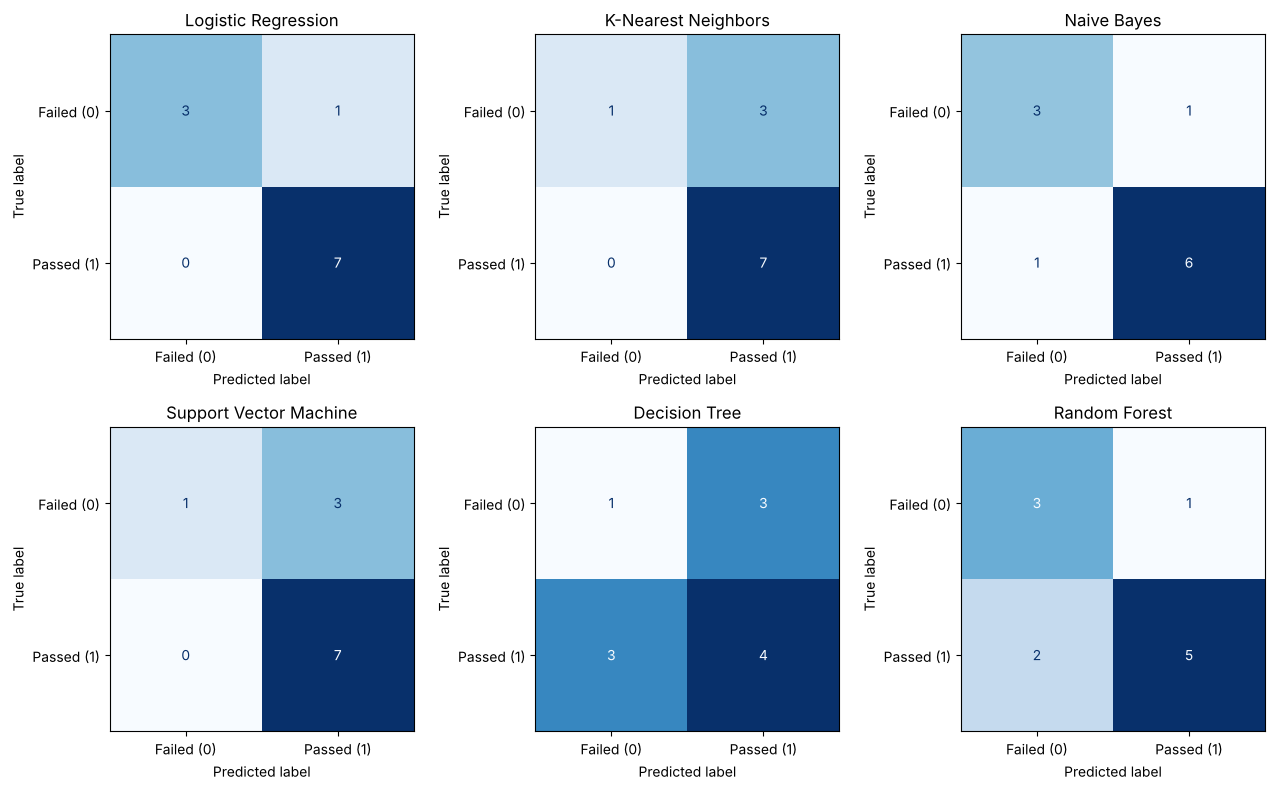

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (name, y_pred) in zip(axes.ravel(), predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=["Failed (0)", "Passed (1)"],
        cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=120)
plt.show()

## 5. Compare the models

### Model comparison table

In [10]:
comparison = (pd.DataFrame(results)
              .sort_values(["F1-score", "Accuracy"], ascending=False)
              .reset_index(drop=True)
              .round(3))
comparison.to_csv("model_comparison.csv", index=False)
comparison

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.909,0.875,1.000,0.933
1,Naive Bayes,0.818,0.857,0.857,0.857
2,K-Nearest Neighbors,0.727,0.700,1.000,0.824
3,Support Vector Machine,0.727,0.700,1.000,0.824
4,Random Forest,0.727,0.833,0.714,0.769
5,Decision Tree,0.455,0.571,0.571,0.571


In [11]:
best_model_name = comparison.loc[0, "Model"]
print("Strongest model on the test set:", best_model_name)
print(comparison.loc[0])

Strongest model on the test set: Logistic Regression
Model        Logistic Regression
Accuracy                   0.909
Precision                  0.875
Recall                       1.0
F1-score                   0.933
Name: 0, dtype: object


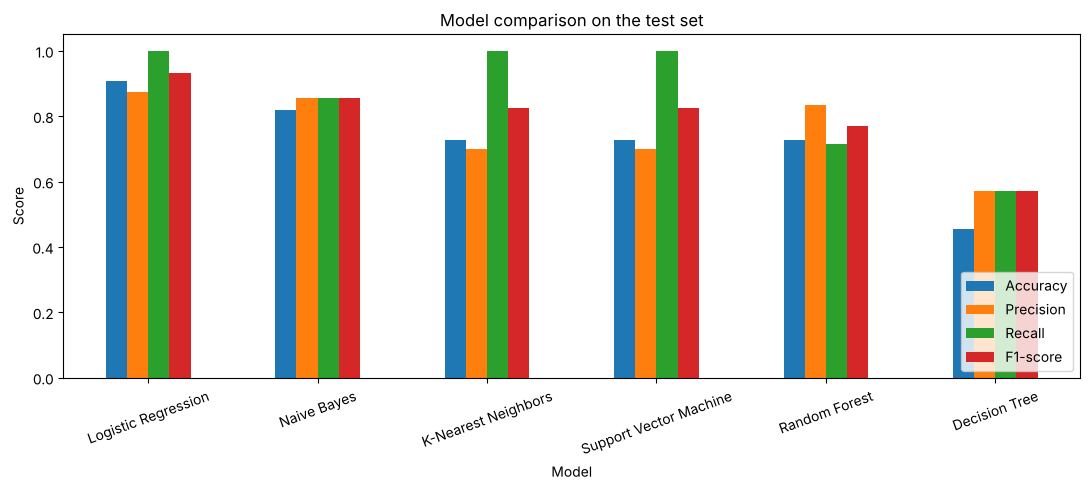

In [12]:
ax = comparison.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar", figsize=(11, 5), ylim=(0, 1.05), rot=20)
ax.set_title("Model comparison on the test set")
ax.set_ylabel("Score")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=120)
plt.show()

Because the test set contains only 11 students, one wrongly classified student changes accuracy by about 9 percentage points. To make the comparison more reliable, 5-fold stratified cross-validation is also computed on the whole cleaned dataset.

In [13]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = {name: cross_val_score(model, X, y, cv=cv, scoring="accuracy")
             for name, model in models.items()}
cv_table = pd.DataFrame({
    "Model": list(cv_scores),
    "CV accuracy (mean)": [s.mean() for s in cv_scores.values()],
    "CV accuracy (std)": [s.std() for s in cv_scores.values()],
}).sort_values("CV accuracy (mean)", ascending=False).reset_index(drop=True).round(3)
cv_table

,Model,CV accuracy (mean),CV accuracy (std)
0,K-Nearest Neighbors,0.789,0.108
1,Logistic Regression,0.753,0.122
2,Naive Bayes,0.753,0.127
3,Random Forest,0.693,0.153
4,Support Vector Machine,0.693,0.070
5,Decision Tree,0.580,0.102


### Differences between the models

| Model | How it works | Strengths / weaknesses on this data |
|---|---|---|
| **Logistic Regression** | Linear model that estimates the probability of passing through a weighted sum of features. | Simple, stable on small data, interpretable coefficients; can only draw a linear boundary. |
| **K-Nearest Neighbors** | Classifies a student by the majority class of the *k* most similar students. | No training phase, but sensitive to scaling and to the small number of neighbours available in 41 rows. |
| **Naive Bayes** | Uses Bayes' theorem assuming features are independent and normally distributed. | Very fast and works with little data, but the independence assumption is rarely true (e.g. study hours and attendance are related). |
| **Support Vector Machine** | Finds the boundary with the maximum margin between classes; the RBF kernel allows non-linear boundaries. | Good on small, scaled datasets, but less interpretable and sensitive to hyperparameters. |
| **Decision Tree** | Splits the data with simple if/else rules on features. | Very interpretable; a deep tree overfits easily, so depth is limited to 3. |
| **Random Forest** | Ensemble of many decision trees trained on random subsets; the final class is a majority vote. | Usually more accurate and stable than a single tree and gives feature importance, but is a "black box" and needs more data to shine. |

## 6. Analyze tree-based models

### 6.1 Decision Tree visualization

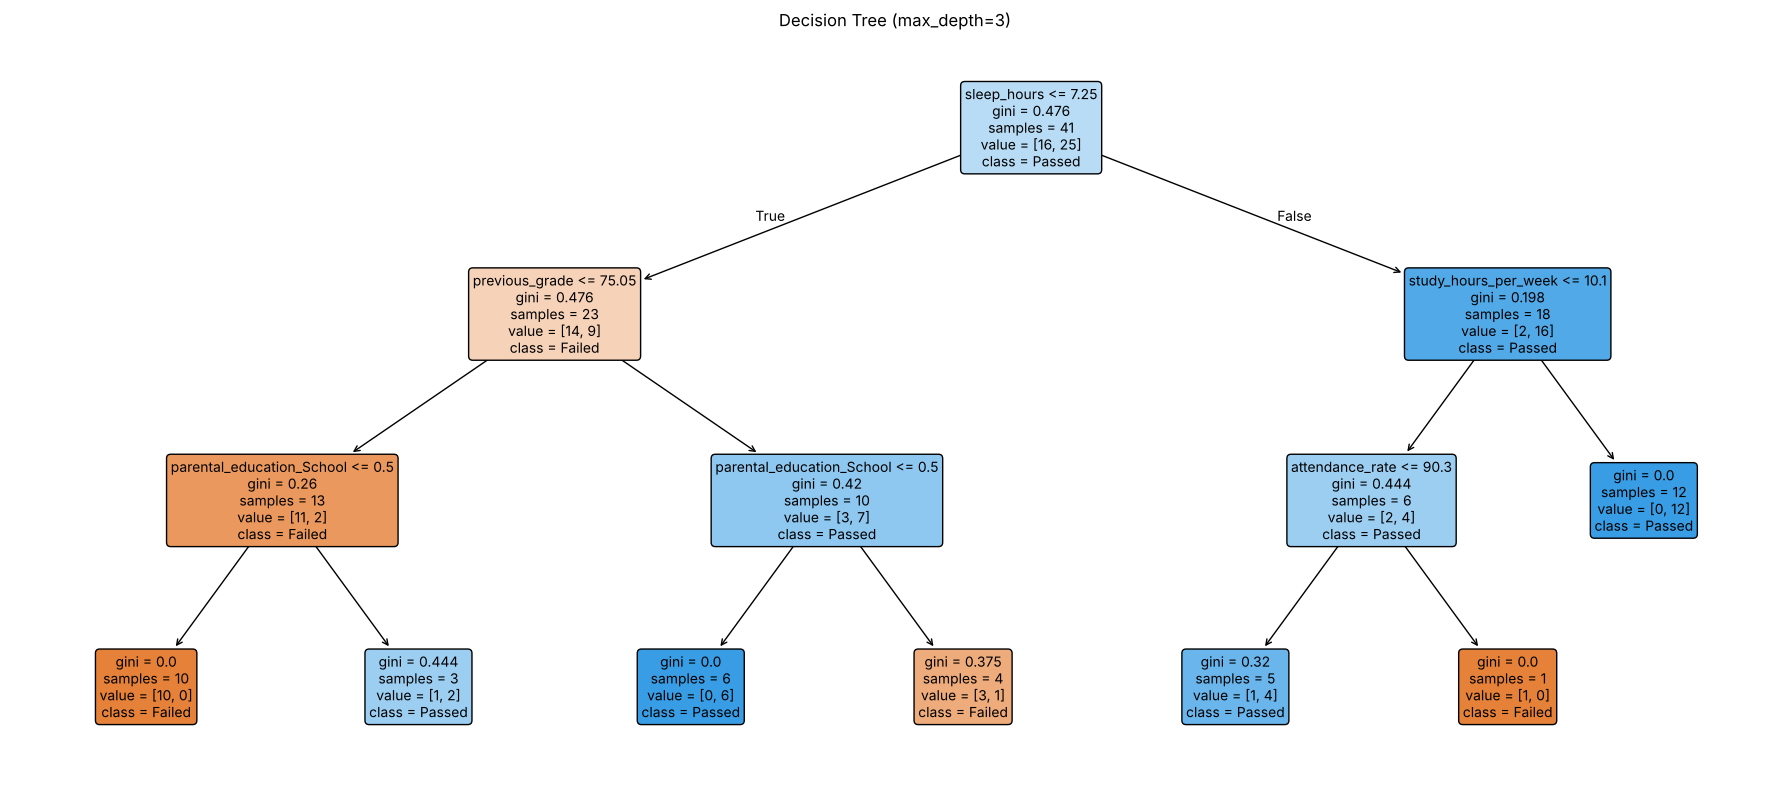

In [14]:
plt.figure(figsize=(18, 8))
plot_tree(models["Decision Tree"], feature_names=X.columns, class_names=["Failed", "Passed"],
          filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree (max_depth=3)")
plt.tight_layout()
plt.savefig("decision_tree.png", dpi=120)
plt.show()

### 6.2 Random Forest feature importance

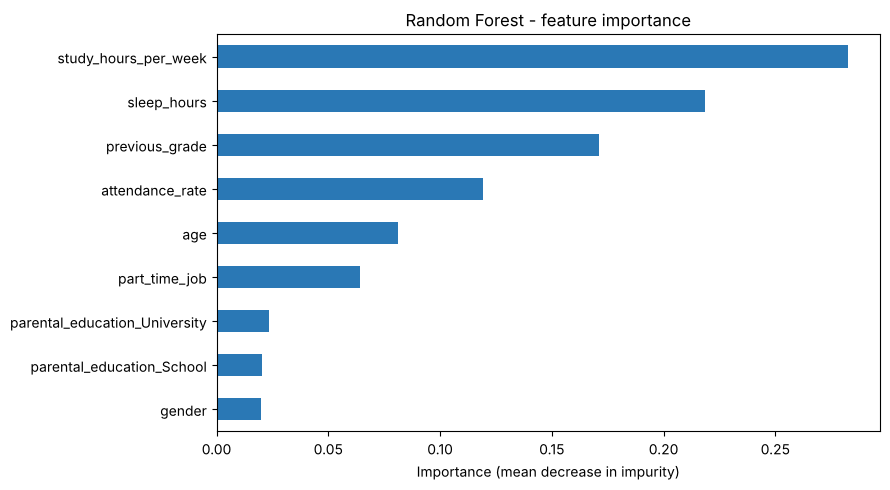

study_hours_per_week             0.283
sleep_hours                      0.218
previous_grade                   0.171
attendance_rate                  0.119
age                              0.081
part_time_job                    0.064
parental_education_University    0.023
parental_education_School        0.020
gender                           0.020
dtype: float64


In [15]:
importances = (pd.Series(models["Random Forest"].feature_importances_, index=X.columns)
               .sort_values(ascending=True))

plt.figure(figsize=(9, 5))
importances.plot(kind="barh", color="#2a78b5")
plt.title("Random Forest - feature importance")
plt.xlabel("Importance (mean decrease in impurity)")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=120)
plt.show()

print(importances.sort_values(ascending=False).round(3))

In [16]:
most_important = importances.idxmax()
print("Most important feature:", most_important, f"({importances.max():.3f})")

Most important feature: study_hours_per_week (0.283)


**Interpretation.** According to the Random Forest, the most important feature is **`study_hours_per_week`**, followed by `sleep_hours`, `previous_grade` and `attendance_rate`. Demographic features (`gender`, `parental_education`) have almost no influence. The single Decision Tree uses the same top features: its root split is `sleep_hours <= 7.25`, then `previous_grade` and `study_hours_per_week`.

## 7. Make a new prediction

A new student that is **not** in the original dataset:

| gender | age | study_hours_per_week | attendance_rate | previous_grade | sleep_hours | part_time_job | parental_education |
|---|---|---|---|---|---|---|---|
| Female | 20 | 15.0 | 88.0 | 74.0 | 7.5 | No | College |

The new observation is encoded exactly like the training data, and the Random Forest and the strongest model are used to predict the class.

In [17]:
new_student = pd.DataFrame([{
    "gender": "Female", "age": 20, "study_hours_per_week": 15.0, "attendance_rate": 88.0,
    "previous_grade": 74.0, "sleep_hours": 7.5, "part_time_job": "No", "parental_education": "College",
}])

new_enc = new_student.copy()
new_enc["gender"] = new_enc["gender"].map({"Female": 0, "Male": 1})
new_enc["part_time_job"] = new_enc["part_time_job"].map({"No": 0, "Yes": 1})
new_enc = pd.get_dummies(new_enc, columns=["parental_education"], dtype=int)
new_enc = new_enc.reindex(columns=X.columns, fill_value=0)  # same columns/order as in training
new_enc

,gender,age,study_hours_per_week,attendance_rate,previous_grade,sleep_hours,part_time_job,parental_education_School,parental_education_University
0,0,20,15.0,88.0,74.0,7.5,0,0,0


In [18]:
for name in dict.fromkeys(["Random Forest", best_model_name]):
    model = models[name]
    pred = model.predict(new_enc)[0]
    proba = model.predict_proba(new_enc)[0, 1] if hasattr(model, "predict_proba") else None
    label = "PASSED (1)" if pred == 1 else "FAILED (0)"
    extra = f" - probability of passing: {proba:.2f}" if proba is not None else ""
    print(f"{name}: {label}{extra}")

Random Forest: PASSED (1) - probability of passing: 0.93
Logistic Regression: PASSED (1) - probability of passing: 0.95


## 8. Conclusion

In [19]:
print("Model comparison (test set):")
print(comparison.to_string(index=False))
print("\nStrongest model on the test set:", best_model_name)
print("Most important feature (Random Forest):", most_important)

Model comparison (test set):
                 Model  Accuracy  Precision  Recall  F1-score
   Logistic Regression     0.909      0.875   1.000     0.933
           Naive Bayes     0.818      0.857   0.857     0.857
   K-Nearest Neighbors     0.727      0.700   1.000     0.824
Support Vector Machine     0.727      0.700   1.000     0.824
         Random Forest     0.727      0.833   0.714     0.769
         Decision Tree     0.455      0.571   0.571     0.571

Strongest model on the test set: Logistic Regression
Most important feature (Random Forest): study_hours_per_week


**Summary of results.** Six classifiers were trained on 41 students and tested on 11 students.

| Model | Accuracy | Precision | Recall | F1-score |
|---|---|---|---|---|
| Logistic Regression | 0.909 | 0.875 | 1.000 | 0.933 |
| Naive Bayes | 0.818 | 0.857 | 0.857 | 0.857 |
| K-Nearest Neighbors | 0.727 | 0.700 | 1.000 | 0.824 |
| Support Vector Machine | 0.727 | 0.700 | 1.000 | 0.824 |
| Random Forest | 0.727 | 0.833 | 0.714 | 0.769 |
| Decision Tree | 0.455 | 0.571 | 0.571 | 0.571 |

**Strongest model:** **Logistic Regression** - accuracy 0.91 and F1-score 0.93 on the test set; it misclassified only one student (one failed student was predicted as passed). It is also among the best in 5-fold cross-validation (≈0.75), together with KNN and Naive Bayes. This suggests the relationship between the features and passing is close to linear: more study hours, more sleep, a higher previous grade and higher attendance increase the chance to pass. The single Decision Tree performed worst - with so few records its rules are unstable and it overfits; the Random Forest fixes part of this by averaging many trees.

**Most important feature:** `study_hours_per_week` (Random Forest importance ≈ 0.28).

**New prediction:** the new student (15 study hours, 88% attendance, previous grade 74, 7.5 h sleep, no job) was predicted to **pass** by both Logistic Regression (probability ≈ 0.95) and Random Forest (≈ 0.93).

**Limitations of a dataset with only ~50 records:**
- the test set has only 11 students, so one error changes accuracy by ~9 percentage points - the ranking of models can change with a different `random_state` (cross-validation gives a different order);
- complex models (Random Forest, SVM, deep trees) cannot show their advantage and easily overfit;
- the classes are imbalanced (34 vs 21 before cleaning), and few failed students are available to learn from;
- the data is synthetic and small, so the results cannot be generalised to real students without collecting more data.